# CSC491 A4 — Berka Bank-Statement Cash-Flow PD Proof of Concept

**Objective:** Train and evaluate an *experimental* default-risk classifier from **historical pre-origination banking transactions**, and export an inference artifact for a web demo. This version **does not use credit scores or credit reports**. Credit-report parsing and a validated combined model are future work.

**Data:** PKDD'99 / Berka (historical Czech banking data, 1990s; **not representative of present-day Canadian lending**). Source: https://github.com/jlacko/berka-dataset

**Critical safeguards:**
- Use **only transactions strictly before** each loan's origination date.
- Primary outcome: **A = completed without default (0), B = completed with default (1)**. **C/D = ongoing at dataset cutoff**, excluded rather than assumed non-default.
- Small completed-loan sample and few defaults: results are unstable; display prevalence and uncertainty. **Do not use this model for real credit approvals.**
- Loan amount and duration are known at underwriting in this prototype but the dataset consists of **approved loans only** (selection bias).



## 1. Imports and reproducibility

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix)

RANDOM_STATE=42
DATA_DIR=Path('/content/berka_data')
DATA_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 100)


## 2. Download original tables

In [ ]:
import urllib.request
base = 'https://raw.githubusercontent.com/jlacko/berka-dataset/master/'
for name in ['loan.asc', 'account.asc', 'trans.asc']:
    path = DATA_DIR/name
    if not path.exists():
        try:
            urllib.request.urlretrieve(base+name, path)
        except Exception as exc:
            print(f'Could not download {name}: {exc}')
    if not path.exists():
        raise FileNotFoundError(f'Upload {name} to {DATA_DIR} and rerun.')
    print(name, f'{path.stat().st_size/1e6:.1f} MB')

loans_raw = pd.read_csv(DATA_DIR/'loan.asc', sep=';', low_memory=False)
accounts_raw = pd.read_csv(DATA_DIR/'account.asc', sep=';', low_memory=False)
transactions_raw = pd.read_csv(DATA_DIR/'trans.asc', sep=';', low_memory=False)
print('Rows:', {'loans':len(loans_raw),'accounts':len(accounts_raw),'transactions':len(transactions_raw)})
display(loans_raw.head(3)); display(transactions_raw.head(3))


loan.asc 0.0 MB
account.asc 0.2 MB
trans.asc 69.4 MB
Rows: {'loans': 682, 'accounts': 4500, 'transactions': 1056320}


,loan_id,account_id,date,amount,duration,payments,status
0,5314,1787,930705,96396,12,8033.0,B
1,5316,1801,930711,165960,36,4610.0,A
2,6863,9188,930728,127080,60,2118.0,A


,trans_id,account_id,date,type,operation,amount,balance,k_symbol,bank,account
0,695247,2378,930101,PRIJEM,VKLAD,700.0,700.0,NaN,NaN,NaN
1,171812,576,930101,PRIJEM,VKLAD,900.0,900.0,NaN,NaN,NaN
2,207264,704,930101,PRIJEM,VKLAD,1000.0,1000.0,NaN,NaN,NaN


## 3. Interpret fields, audit loan statuses and dates


In [ ]:
def parse_berka_date(series):
    z = pd.to_numeric(series, errors='coerce').astype('Int64').astype('string').str.zfill(6)
    # Berka data YYMMDD dates are from the 1990s.
    return pd.to_datetime('19'+z, format='%Y%m%d', errors='coerce')

loans = loans_raw.copy()
trans = transactions_raw.copy()
accounts = accounts_raw.copy()
loans['loan_date'] = parse_berka_date(loans['date'])
trans['tx_date'] = parse_berka_date(trans['date'])
accounts['account_open_date'] = parse_berka_date(accounts['date'])

print('Loan statuses in FULL file (not model population):')
display(loans.groupby('status').agg(n=('loan_id','size'), earliest=('loan_date','min'), latest=('loan_date','max')))
print('Date nulls:', loans['loan_date'].isna().sum(), trans['tx_date'].isna().sum())
assert loans['loan_date'].notna().all() and trans['tx_date'].notna().all()
print('Transaction types:'); display(trans['type'].value_counts(dropna=False))
print('Transaction operations:'); display(trans['operation'].value_counts(dropna=False).head(20))


Loan statuses in FULL file (not model population):


,n,earliest,latest
status,,,
A,203,1993-07-11,1997-12-28
B,31,1993-07-05,1997-09-21
C,403,1994-01-20,1998-12-08
D,45,1994-07-19,1998-10-14


Date nulls: 0 0
Transaction types:


,count
type,
VYDAJ,634571
PRIJEM,405083
VYBER,16666


Transaction operations:


,count
operation,
VYBER,434918
PREVOD NA UCET,208283
NaN,183114
VKLAD,156743
PREVOD Z UCTU,65226
VYBER KARTOU,8036


## 4. Define labels and build pre-loan cash-flow features

For every loan, compute features within **[loan date − 180 days, loan date)**; all deposits/withdrawals on or after origination are excluded. This is a **6-month feature window**; the available number of observed days and transaction count are audited. A 90-day historical median of daily post-transaction balances serves as a *proxy* for balance persistence. It is **not** a verified full daily-balance series before the first observed transaction.

In [ ]:
status_map = {'A':0, 'B':1}  # only FINISHED loans with known final outcomes
eligible_loans = loans.loc[loans['status'].isin(status_map)].copy()
eligible_loans['DEFAULT'] = eligible_loans['status'].map(status_map).astype(int)
print('Completed loan target distribution:'); display(eligible_loans['DEFAULT'].value_counts().rename(index={0:'non-default',1:'default'}))
print('Completed loan default rate:', round(eligible_loans['DEFAULT'].mean(),4))

# In original dataset: PRIJEM=inflow; VYDAJ=outflow; VYBER=cash withdrawal.
trans['amount'] = pd.to_numeric(trans['amount'], errors='coerce')
trans['balance'] = pd.to_numeric(trans['balance'], errors='coerce')
trans['is_inflow'] = trans['type'].eq('PRIJEM')
trans['is_outflow'] = trans['type'].isin(['VYDAJ', 'VYBER'])
print('Unrecognized transaction types:', trans.loc[~(trans.is_inflow|trans.is_outflow),'type'].value_counts().to_dict())
trans = trans.sort_values(['account_id','tx_date','trans_id']).copy()

FEATURE_NAMES = [
    'tx_count_180d','history_days_180d','observed_months_180d',
    'total_inflow_180d','total_outflow_180d','net_flow_180d',
    'avg_monthly_inflow_180d','avg_monthly_outflow_180d','avg_monthly_net_180d',
    'std_monthly_net_180d','income_cv_180d','inflow_months_180d',
    'median_tx_balance_180d','min_tx_balance_180d',
    'median_daily_observed_balance_90d','recent_large_inflow_share_30d',
    'negative_balance_tx_share_180d','median_inflow_size_180d'
]

def cashflow_features(tx, as_of_date, window_days=180):
    """Feature builder shared between TRAINING and demo INFERENCE.
    tx must have tx_date, amount, balance, is_inflow, is_outflow.
    Must contain transactions for ONE account (or a properly deduplicated aggregation).
    """
    as_of_date = pd.Timestamp(as_of_date)
    t = tx.loc[(tx['tx_date'] >= as_of_date-pd.Timedelta(days=window_days)) &
               (tx['tx_date'] < as_of_date)].copy()
    out = {k:np.nan for k in FEATURE_NAMES}
    out['tx_count_180d'] = len(t)
    if t.empty:
        out.update({'history_days_180d':0,'observed_months_180d':0,'inflow_months_180d':0})
        return out
    t = t.sort_values('tx_date')
    out['history_days_180d'] = int((t['tx_date'].max()-t['tx_date'].min()).days+1)
    inflow = t.loc[t['is_inflow']]
    outflow = t.loc[t['is_outflow']]
    received = float(inflow['amount'].sum())
    paid = float(outflow['amount'].sum())
    out['total_inflow_180d']=received
    out['total_outflow_180d']=paid
    out['net_flow_180d']=received-paid
    # Six fixed calendar-like 30-day bins, including bins with zero transactions.
    day_age = (as_of_date-t['tx_date']).dt.days
    t['bin30'] = np.minimum((day_age-1)//30, 5)
    monthly = pd.DataFrame({'inflow':np.zeros(6),'outflow':np.zeros(6)})
    for flag,col in [('is_inflow','inflow'),('is_outflow','outflow')]:
        monthly[col] = t.loc[t[flag]].groupby('bin30')['amount'].sum().reindex(range(6),fill_value=0).to_numpy()
    net = monthly['inflow']-monthly['outflow']
    out['observed_months_180d']=int(t['bin30'].nunique())
    out['inflow_months_180d']=int((monthly['inflow']>0).sum())
    out['avg_monthly_inflow_180d']=float(monthly['inflow'].mean())
    out['avg_monthly_outflow_180d']=float(monthly['outflow'].mean())
    out['avg_monthly_net_180d']=float(net.mean())
    out['std_monthly_net_180d']=float(net.std(ddof=0))
    out['income_cv_180d']=float(monthly['inflow'].std(ddof=0)/(monthly['inflow'].mean()+1))
    out['median_tx_balance_180d']=float(t['balance'].median())
    out['min_tx_balance_180d']=float(t['balance'].min())
    t90 = t.loc[t['tx_date']>=as_of_date-pd.Timedelta(days=90)]
    daily_end = t90.groupby('tx_date')['balance'].last()
    out['median_daily_observed_balance_90d']=float(daily_end.median()) if not daily_end.empty else np.nan
    out['negative_balance_tx_share_180d']=float((t['balance']<0).mean())
    out['median_inflow_size_180d']=float(inflow['amount'].median()) if len(inflow) else np.nan
    recent_inflow = inflow.loc[inflow['tx_date']>=as_of_date-pd.Timedelta(days=30),'amount']
    # Relative to own history (for exploratory flag, NOT an established regulatory threshold).
    benchmark = inflow['amount'].median() if len(inflow) else np.nan
    large = recent_inflow.loc[recent_inflow > 3*benchmark] if pd.notna(benchmark) else pd.Series(dtype=float)
    out['recent_large_inflow_share_30d']=float(large.sum()/(recent_inflow.sum()+1))
    return out


Completed loan target distribution:


,count
DEFAULT,
non-default,203
default,31


Completed loan default rate: 0.1325
Unrecognized transaction types: {}


## 5. Construct one row per loan and audit history availability

`account_id` identifies the account where a loan was recorded. **This does not prove multi-bank completeness**. The model should not claim to have detected all financial accounts.

In [ ]:
account_groups = {aid:g for aid,g in trans.groupby('account_id',sort=False)}
rows=[]
for r in eligible_loans.itertuples(index=False):
    t = account_groups.get(r.account_id,trans.iloc[:0])
    feat = cashflow_features(t, r.loan_date)
    rows.append({'loan_id':r.loan_id,'account_id':r.account_id,'loan_date':r.loan_date,
                 'loan_amount':float(r.amount),'loan_duration':float(r.duration),
                 'DEFAULT':int(r.DEFAULT), **feat})
model_df=pd.DataFrame(rows).sort_values('loan_date').reset_index(drop=True)
assert len(model_df)==len(eligible_loans)
print('Loan level shape:',model_df.shape)
print('Cash-flow coverage:'); display(model_df[['tx_count_180d','history_days_180d','observed_months_180d']].describe())
print('Default by coverage:')
display(model_df.assign(coverage=pd.cut(model_df['tx_count_180d'],[-1,0,4,9,99999],labels=['0','1–4','5–9','10+']))
        .groupby('coverage',observed=True)['DEFAULT'].agg(['size','sum','mean']))

# Restrict to loans with at least some pre-loan history. This changes the sample!
MIN_TX=5
analysis_df=model_df.loc[model_df['tx_count_180d']>=MIN_TX].copy()
print(f'Included {len(analysis_df)} of {len(model_df)} completed loans with >= {MIN_TX} pre-loan tx')
print('Class counts:',analysis_df['DEFAULT'].value_counts().to_dict())
if analysis_df['DEFAULT'].nunique()!=2 or analysis_df['DEFAULT'].value_counts().min()<6:
    raise ValueError('Too few defaults/non-defaults for meaningful model evaluation; inspect filtering, do not invent results.')
display(analysis_df.head())


Loan level shape: (234, 24)
Cash-flow coverage:


,tx_count_180d,history_days_180d,observed_months_180d
count,234.000000,234.000000,234.000000
mean,39.012821,166.008547,5.884615
std,13.160769,16.275522,0.392443
min,4.000000,91.000000,4.000000
25%,31.250000,164.000000,6.000000
50%,40.000000,171.000000,6.000000
75%,48.000000,176.000000,6.000000
max,68.000000,180.000000,6.000000


Default by coverage:


,size,sum,mean
coverage,,,
1–4,1,1,1.000
5–9,1,1,1.000
10+,232,29,0.125


Included 233 of 234 completed loans with >= 5 pre-loan tx
Class counts: {0: 203, 1: 30}


,loan_id,account_id,loan_date,loan_amount,loan_duration,DEFAULT,tx_count_180d,history_days_180d,observed_months_180d,total_inflow_180d,total_outflow_180d,net_flow_180d,avg_monthly_inflow_180d,avg_monthly_outflow_180d,avg_monthly_net_180d,std_monthly_net_180d,income_cv_180d,inflow_months_180d,median_tx_balance_180d,min_tx_balance_180d,median_daily_observed_balance_90d,recent_large_inflow_share_30d,negative_balance_tx_share_180d,median_inflow_size_180d
1,5316,1801,1993-07-11,165960.0,36.0,0,37,147,5,229893.7,177684.8,52208.9,38315.616667,29614.133333,8701.483333,43096.094207,0.963233,5,52208.90,700.0,50625.85,0.740296,0.0,8368.0
2,6863,9188,1993-07-28,127080.0,60.0,0,24,164,6,75146.0,54873.0,20273.0,12524.333333,9145.500000,3378.833333,9555.541024,0.459289,6,30463.95,800.0,34208.30,0.980982,0.0,139.8
3,5325,1843,1993-08-03,105804.0,36.0,0,24,175,6,119309.8,86017.2,33292.6,19884.966667,14336.200000,5548.766667,8403.073754,0.166982,6,39807.25,18632.0,47779.20,0.000000,0.0,10766.0
4,7240,11013,1993-09-06,274740.0,60.0,0,26,172,6,275727.1,235214.0,40513.1,45954.516667,39202.333333,6752.183333,16541.681267,0.171922,6,51957.55,35844.0,51491.90,0.000000,0.0,21249.4
5,6687,8261,1993-09-13,87840.0,24.0,0,17,121,5,102647.8,58800.0,43847.8,17107.966667,9800.000000,7307.966667,17880.850032,0.746979,5,57602.60,500.0,61286.50,0.981232,0.0,263.4


## 6. EDA and leakage checks

Data availability / missing rates:


,missing_fraction
tx_count_180d,0.0
history_days_180d,0.0
observed_months_180d,0.0
total_inflow_180d,0.0
total_outflow_180d,0.0
net_flow_180d,0.0
avg_monthly_inflow_180d,0.0
avg_monthly_outflow_180d,0.0
avg_monthly_net_180d,0.0
std_monthly_net_180d,0.0


Target distribution:


,count
DEFAULT,
No default,203
Default,30


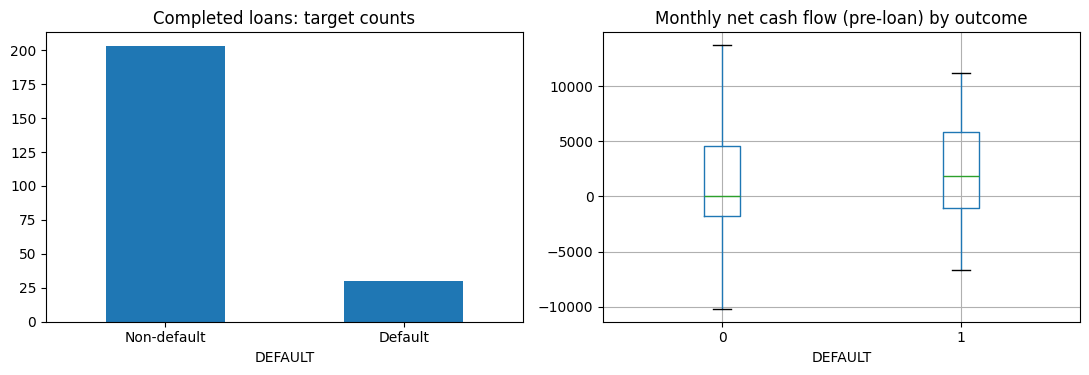

Sample pre-origination cutoff assertions passed.


In [ ]:
print('Data availability / missing rates:')
display(analysis_df[FEATURE_NAMES].isna().mean().sort_values(ascending=False).to_frame('missing_fraction'))
print('Target distribution:')
display(analysis_df['DEFAULT'].value_counts().rename(index={0:'No default',1:'Default'}))
fig,axes=plt.subplots(1,2,figsize=(11,4))
analysis_df['DEFAULT'].value_counts().sort_index().plot(kind='bar',ax=axes[0],title='Completed loans: target counts')
axes[0].set_xticklabels(['Non-default','Default'],rotation=0)
analysis_df.boxplot(column='avg_monthly_net_180d',by='DEFAULT',ax=axes[1],showfliers=False)
axes[1].set_title('Monthly net cash flow (pre-loan) by outcome'); axes[1].set_xlabel('DEFAULT')
plt.suptitle(''); plt.tight_layout();plt.show()

# Explicit check: every transaction used by feature function occurs strictly pre-origination.
for _,r in eligible_loans[['account_id','loan_date']].head(10).iterrows():
    raw=account_groups.get(r['account_id'],trans.iloc[:0])
    sliced=raw.loc[(raw['tx_date']>=r['loan_date']-pd.Timedelta(days=180)) & (raw['tx_date']<r['loan_date'])]
    assert sliced.empty or sliced['tx_date'].max()<r['loan_date']
print('Sample pre-origination cutoff assertions passed.')


## 7. Train three models on **the same split**

A: loan request fields only; B: cash-flow features only; C: combined. *A is not a credit-score baseline.* We use stratified random train/test split for a reproducible small-sample demo; chronological generalization is **not** established. Because the sample is small, the notebook also prints results by origination period for inspection.

In [ ]:
basic_cols=['loan_amount','loan_duration']
cash_cols=FEATURE_NAMES.copy()
feature_sets={'A: Loan terms baseline':basic_cols,
              'B: Cash flow only':cash_cols,
              'C: Loan terms + cash flow':basic_cols+cash_cols}
Y=analysis_df['DEFAULT']
all_idx=np.arange(len(analysis_df))
train_idx,test_idx=train_test_split(all_idx,test_size=0.25,stratify=Y,random_state=RANDOM_STATE)
print('Train:',len(train_idx),'Test:',len(test_idx))
print('Defaults train/test:',int(Y.iloc[train_idx].sum()),int(Y.iloc[test_idx].sum()))

algorithms={
 'Logistic Regression':lambda:Pipeline([
     ('imputer',SimpleImputer(strategy='median',add_indicator=False)),
     ('scaler',RobustScaler()),
     ('classifier',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=RANDOM_STATE))]),
 'Random Forest':lambda:Pipeline([
     ('imputer',SimpleImputer(strategy='median')),
     ('classifier',RandomForestClassifier(n_estimators=200,min_samples_leaf=5,
                                          class_weight='balanced_subsample',random_state=RANDOM_STATE,n_jobs=-1))])
}
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=RANDOM_STATE)
scoring={'ROC_AUC':'roc_auc','PR_AUC':'average_precision','Neg_Brier':'neg_brier_score'}
cv_rows=[]
for group,cols in feature_sets.items():
    for name,factory in algorithms.items():
        scores=cross_validate(factory(),analysis_df.iloc[train_idx][cols],Y.iloc[train_idx],
                              cv=cv,scoring=scoring,error_score='raise',n_jobs=-1)
        cv_rows.append({'features':group,'algorithm':name,
                        'cv_roc_auc':scores['test_ROC_AUC'].mean(),
                        'cv_pr_auc':scores['test_PR_AUC'].mean(),
                        'cv_brier':-scores['test_Neg_Brier'].mean(),
                        'cv_roc_sd':scores['test_ROC_AUC'].std()})
cv_results=pd.DataFrame(cv_rows).sort_values('cv_roc_auc',ascending=False)
display(cv_results.round(4))


Train: 174 Test: 59
Defaults train/test: 22 8


,features,algorithm,cv_roc_auc,cv_pr_auc,cv_brier,cv_roc_sd
2,B: Cash flow only,Logistic Regression,0.8433,0.7124,0.1460,0.0741
4,C: Loan terms + cash flow,Logistic Regression,0.8401,0.6842,0.1381,0.0638
3,B: Cash flow only,Random Forest,0.8225,0.4823,0.1087,0.1036
5,C: Loan terms + cash flow,Random Forest,0.8144,0.5317,0.1064,0.1380
0,A: Loan terms baseline,Logistic Regression,0.6752,0.3302,0.2193,0.0950
1,A: Loan terms baseline,Random Forest,0.6004,0.2582,0.1806,0.1228


## 8. Holdout test evaluation

To keep comparisons fair, **evaluate every combination on the same untouched holdout**. Selection of a future production model would need stronger validation; the sorted test metrics are not evidence of a newly optimized winner.

Test prevalence: 0.1356 (baseline Average Precision)


,features,algorithm,test_roc_auc,test_pr_auc,test_brier
1,A: Loan terms baseline,Random Forest,0.7904,0.3783,0.1486
3,B: Cash flow only,Random Forest,0.7868,0.4171,0.1201
5,C: Loan terms + cash flow,Random Forest,0.7794,0.4360,0.1181
2,B: Cash flow only,Logistic Regression,0.7574,0.4181,0.1768
4,C: Loan terms + cash flow,Logistic Regression,0.7574,0.3520,0.1823
0,A: Loan terms baseline,Logistic Regression,0.5650,0.2268,0.2278


CV-selected: ('B: Cash flow only', 'Logistic Regression')
Test ROC-AUC: 0.757
Test PR-AUC: 0.418
Test Brier: 0.177


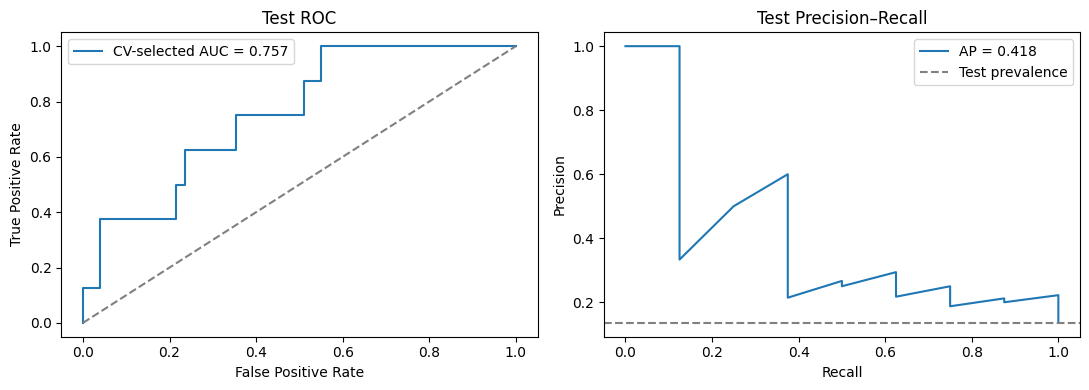

Confusion matrix at arbitrary 0.5 threshold (NOT a lending policy):
[[38 13]
 [ 3  5]]


In [ ]:
holdout_rows=[]; trained={}; preds={}
for group,cols in feature_sets.items():
    for name,factory in algorithms.items():
        key=(group,name)
        p=factory().fit(analysis_df.iloc[train_idx][cols],Y.iloc[train_idx])
        prob=p.predict_proba(analysis_df.iloc[test_idx][cols])[:,1]
        trained[key]=p; preds[key]=prob
        holdout_rows.append({'features':group,'algorithm':name,
                             'test_roc_auc':roc_auc_score(Y.iloc[test_idx],prob),
                             'test_pr_auc':average_precision_score(Y.iloc[test_idx],prob),
                             'test_brier':brier_score_loss(Y.iloc[test_idx],prob)})
holdout=pd.DataFrame(holdout_rows).sort_values('test_roc_auc',ascending=False)
print('Test prevalence:',round(Y.iloc[test_idx].mean(),4),'(baseline Average Precision)')
display(holdout.round(4))

# Choose candidate solely by TRAINING CV, never by looking at test results.
winner=cv_results.iloc[0]
BEST_KEY=(winner['features'],winner['algorithm'])
BEST_COLS=feature_sets[BEST_KEY[0]]
model=trained[BEST_KEY]
pred=preds[BEST_KEY]
y_test=Y.iloc[test_idx]
print('CV-selected:',BEST_KEY)
print('Test ROC-AUC:',round(roc_auc_score(y_test,pred),3))
print('Test PR-AUC:',round(average_precision_score(y_test,pred),3))
print('Test Brier:',round(brier_score_loss(y_test,pred),3))
fig,axes=plt.subplots(1,2,figsize=(11,4))
fpr,tpr,_=roc_curve(y_test,pred)
axes[0].plot(fpr,tpr,label=f'CV-selected AUC = {roc_auc_score(y_test,pred):.3f}')
axes[0].plot([0,1],[0,1],'--',color='gray');axes[0].set(xlabel='False Positive Rate',ylabel='True Positive Rate',title='Test ROC')
axes[0].legend()
precision,recall,_=precision_recall_curve(y_test,pred)
axes[1].plot(recall,precision,label=f'AP = {average_precision_score(y_test,pred):.3f}')
axes[1].axhline(y_test.mean(),ls='--',color='gray',label='Test prevalence')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Test Precision–Recall')
axes[1].legend();plt.tight_layout();plt.show()
print('Confusion matrix at arbitrary 0.5 threshold (NOT a lending policy):')
print(confusion_matrix(y_test,pred>=0.5))


## 9. Uncertainty and out-of-time check

The bootstrap interval quantifies test-sample variability, not transportability to Canada. A truly valid chronological deployment test would need enough known-outcome cases and a label horizon matched to the decision date.

In [ ]:
rng=np.random.default_rng(RANDOM_STATE)
boot=[]
truth=y_test.to_numpy()
for i in range(1000):
    ix=rng.choice(len(truth),size=len(truth),replace=True)
    if len(np.unique(truth[ix]))<2: continue
    boot.append(roc_auc_score(truth[ix],pred[ix]))
print('Bootstrap holdout ROC-AUC 95% percentile interval:',np.round(np.quantile(boot,[.025,.975]),3) if boot else 'Unavailable')
print('Holdout origination years and event counts:')
display(analysis_df.iloc[test_idx].assign(year=lambda q:q.loan_date.dt.year)
        .groupby('year')['DEFAULT'].agg(['size','sum','mean']))


Bootstrap holdout ROC-AUC 95% percentile interval: [0.581 0.912]
Holdout origination years and event counts:


,size,sum,mean
year,,,
1993,4,0,0.000000
1994,21,4,0.190476
1995,13,1,0.076923
1996,8,3,0.375000
1997,13,0,0.000000


## 10. Export for web backend and test a one-account historical CSV



In [ ]:
artifact={
  'model':model,
  'feature_columns':BEST_COLS,
  'feature_set':BEST_KEY[0],
  'algorithm':BEST_KEY[1],
  'purpose':'Historical Berka educational proof of concept; NOT real underwriting',
  'label':'A=finished non-default (0); B=finished default (1)',
  'currency':'CZK (historical); do not assume CAD',
  'window_days':180,
  'minimum_history_transactions':MIN_TX,
}
joblib.dump(artifact,'/content/berka_cashflow_pd_demo.joblib')
analysis_df.to_csv('/content/berka_preloan_features_audit.csv',index=False)
print('Saved model: /content/berka_cashflow_pd_demo.joblib')
print('Saved audited features: /content/berka_preloan_features_audit.csv')

def predict_single_account_statement(statement, loan_date, loan_amount, loan_duration, saved_artifact=artifact):
    """Demo-only input: statement columns date, amount, balance, type.
    type must be PRIJEM, VYDAJ or VYBER; amount positive magnitude, original CZK convention.
    Uploads using other currencies, schemas or multiple accounts require preprocessing/validation.
    """
    required={'date','amount','balance','type'}
    if not required.issubset(statement.columns):
        raise ValueError(f'Statement must have columns {sorted(required)}')
    t=statement.copy()
    t['tx_date']=pd.to_datetime(t['date'],errors='coerce')
    t['amount']=pd.to_numeric(t['amount'],errors='coerce')
    t['balance']=pd.to_numeric(t['balance'],errors='coerce')
    if t[['tx_date','amount','balance']].isna().any().any() or (t['amount']<0).any():
        raise ValueError('Invalid date, amount or balance. Expected nonnegative transaction magnitude.')
    if not t['type'].isin(['PRIJEM','VYDAJ','VYBER']).all():
        raise ValueError('Unexpected transaction type')
    t['is_inflow']=t['type'].eq('PRIJEM')
    t['is_outflow']=t['type'].isin(['VYDAJ','VYBER'])
    f=cashflow_features(t,pd.Timestamp(loan_date))
    if f['tx_count_180d']<saved_artifact['minimum_history_transactions']:
        raise ValueError('Insufficient pre-loan history; request more records.')
    inputs={'loan_amount':float(loan_amount),'loan_duration':float(loan_duration),**f}
    row=pd.DataFrame([inputs])[saved_artifact['feature_columns']]
    return {'experimental_risk_score':float(saved_artifact['model'].predict_proba(row)[0,1]),
            'cashflow_features':f,
            'warning':'Research prototype only; not calibrated for actual borrower decisions.'}

# Example using one pre-loan account from actual Berka sample; target is never sent into prediction.
example=analysis_df.iloc[0]
sample_tx=account_groups[example['account_id']].loc[
    lambda t:(t.tx_date>=example['loan_date']-pd.Timedelta(days=180)) & (t.tx_date<example['loan_date'])
].copy()
sample_statement=sample_tx[['tx_date','amount','balance','type']].rename(columns={'tx_date':'date'})
example_result=predict_single_account_statement(sample_statement,example['loan_date'],example['loan_amount'],example['loan_duration'])
print('Example experimental score:',round(example_result['experimental_risk_score'],4))
print(example_result['warning'])
sample_statement.to_csv('/content/berka_statement_demo.csv',index=False)
print('Example CSV: /content/berka_statement_demo.csv')


Saved model: /content/berka_cashflow_pd_demo.joblib
Saved audited features: /content/berka_preloan_features_audit.csv
Example experimental score: 0.5231
Research prototype only; not calibrated for actual borrower decisions.
Example CSV: /content/berka_statement_demo.csv
